In [1]:
# !pip install shap lime captum dice_ml torch torchvision scikit-learn pandas matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from IPython.display import display, HTML

import shap
import lime.lime_tabular
import dice_ml
from captum.attr import Saliency, IntegratedGradients, NoiseTunnel
from sklearn.datasets import fetch_california_housing, fetch_openml
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.inspection import PartialDependenceDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
shap.initjs()

/home/evanoreilly/Module_Code/ai_code/XAI/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Global Explanation: Partial Dependence Plot ---


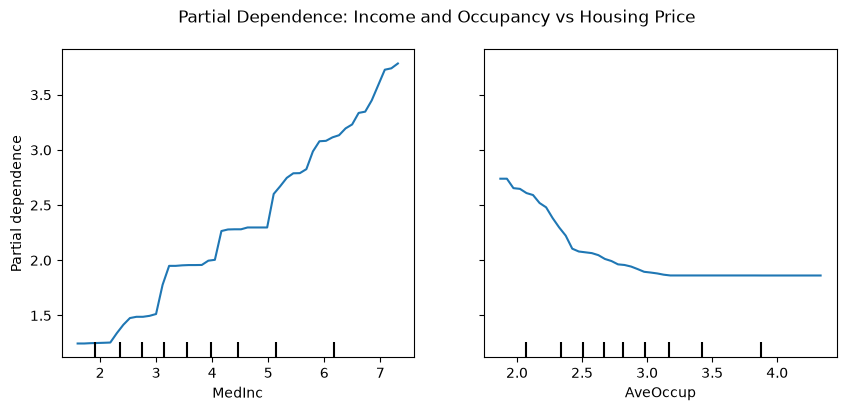


--- Global Explanation: SHAP Summary Plot ---


/tmp/ipykernel_505687/1087910553.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test)


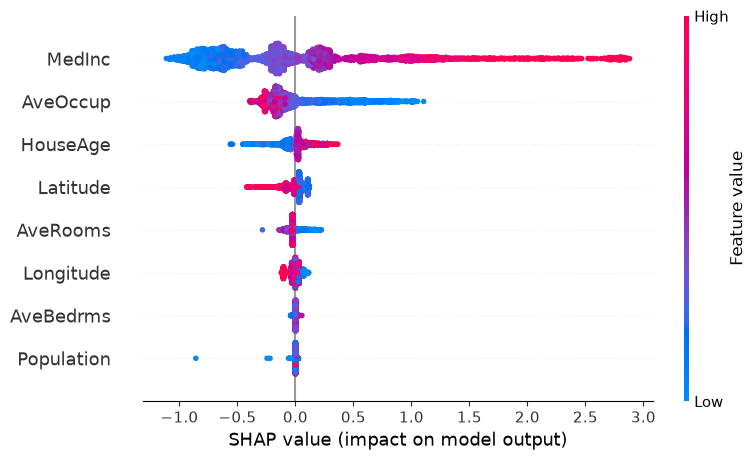

In [2]:
# 1. Load Data & Train Model
housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_reg = RandomForestRegressor(n_estimators=50, max_depth=5, random_state=42)
rf_reg.fit(X_train, y_train)

# 2. Global Explanations: Partial Dependence Plots (PDP)
print("--- Global Explanation: Partial Dependence Plot ---")
fig, ax = plt.subplots(figsize=(10, 4))
PartialDependenceDisplay.from_estimator(
    rf_reg, X_train, features=['MedInc', 'AveOccup'], grid_resolution=50, ax=ax
)
plt.suptitle("Partial Dependence: Income and Occupancy vs Housing Price")
plt.show()

# 3. Global Explanations: SHAP Summary Plot
print("\n--- Global Explanation: SHAP Summary Plot ---")
explainer_shap = shap.TreeExplainer(rf_reg)
shap_values = explainer_shap(X_test)
shap.summary_plot(shap_values, X_test)

/home/evanoreilly/Module_Code/ai_code/XAI/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Actual Price: 0.713 | Predicted: 1.337

--- Local Explanation: SHAP Waterfall ---


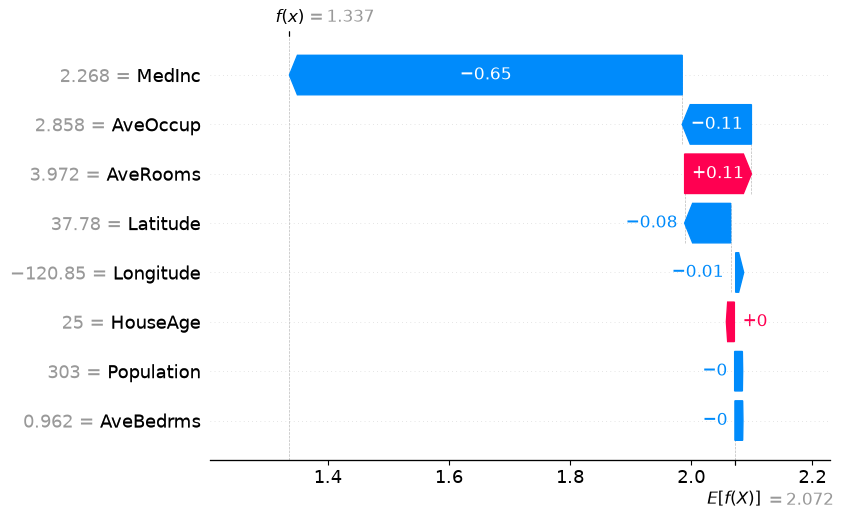


--- Local Explanation: LIME ---


/home/evanoreilly/Module_Code/ai_code/XAI/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [3]:
sample_idx = 42 # Picking a specific house
sample_instance = X_test.iloc[sample_idx]

print(f"Actual Price: {y_test.iloc[sample_idx]:.3f} | Predicted: {rf_reg.predict([sample_instance])[0]:.3f}")

# SHAP Local Waterfall
print("\n--- Local Explanation: SHAP Waterfall ---")
shap.plots.waterfall(shap_values[sample_idx])

# LIME Local Surrogate
print("\n--- Local Explanation: LIME ---")
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    mode='regression',
    random_state=42
)
lime_exp = explainer_lime.explain_instance(
    data_row=sample_instance.to_numpy(), 
    predict_fn=rf_reg.predict
)

display(HTML(lime_exp.as_html(show_table=True)))


--- Deep Learning Gradient Attribution ---


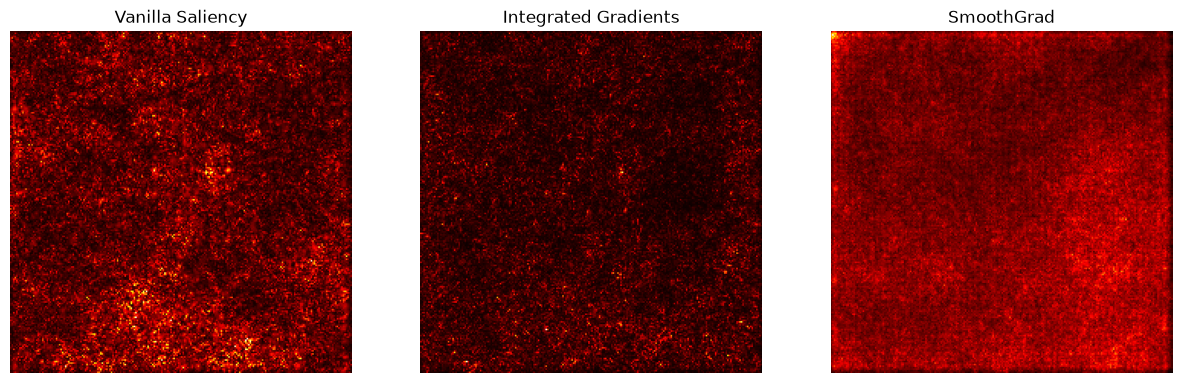

In [4]:
# 1. Load Pre-trained Vision Model
model = resnet18(weights=ResNet18_Weights.DEFAULT).eval()

# 2. Create a dummy image (In reality, load a sample image like a dog/cat)
# Using a generated pattern to represent an image tensor for this demo
input_tensor = torch.rand(1, 3, 224, 224, requires_grad=True)

# 3. Saliency (Vanilla Gradients)
saliency = Saliency(model)
sal_attr = saliency.attribute(input_tensor, target=258) # 258 = Samoyed dog class
sal_map = np.transpose(sal_attr.squeeze().cpu().detach().numpy(), (1, 2, 0))

# 4. Integrated Gradients
ig = IntegratedGradients(model)
ig_attr = ig.attribute(input_tensor, target=258, n_steps=50)
ig_map = np.transpose(ig_attr.squeeze().cpu().detach().numpy(), (1, 2, 0))

# 5. SmoothGrad (NoiseTunnel)
noise_tunnel = NoiseTunnel(saliency)
sg_attr = noise_tunnel.attribute(input_tensor, nt_type='smoothgrad', target=258, nt_samples=10)
sg_map = np.transpose(sg_attr.squeeze().cpu().detach().numpy(), (1, 2, 0))

# Visualization Function
def plot_maps(maps, titles):
    fig, axes = plt.subplots(1, len(maps), figsize=(15, 5))
    for ax, m, title in zip(axes, maps, titles):
        # Normalize for visualization
        m_norm = np.clip(np.sum(np.abs(m), axis=2), 0, 1)
        ax.imshow(m_norm, cmap='hot')
        ax.set_title(title)
        ax.axis('off')
    plt.show()

print("\n--- Deep Learning Gradient Attribution ---")
plot_maps([sal_map, ig_map, sg_map], ["Vanilla Saliency", "Integrated Gradients", "SmoothGrad"])


--- Sanity Check: Model with Randomized Top Layer ---
Notice how Vanilla Saliency still looks highly structured (like an edge detector) despite the model being broken.


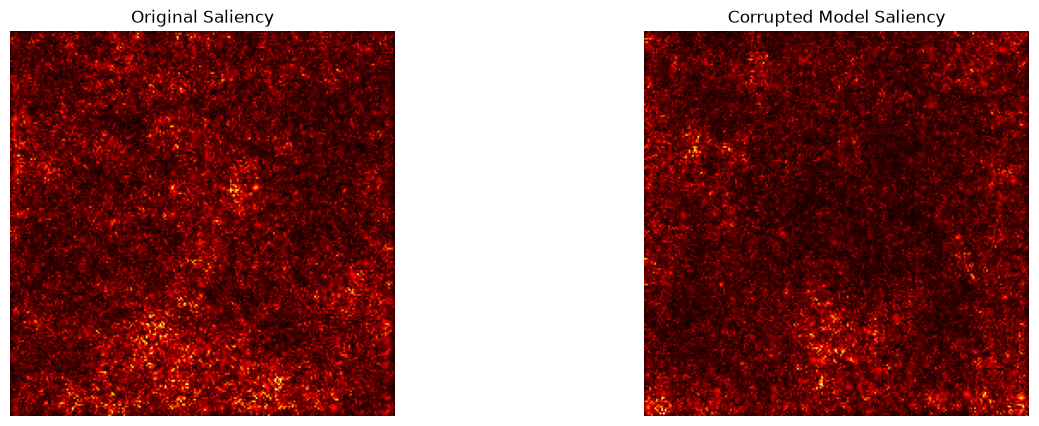

In [5]:
# Slide 22: Adebayo et al. Sanity Check
# Randomize the weights of the top fully connected layer
model.fc.weight.data.normal_(mean=0.0, std=1.0)
model.fc.bias.data.zero_()

# Recompute Saliency on the corrupted model
saliency_corrupted = Saliency(model)
sal_attr_corrupted = saliency_corrupted.attribute(input_tensor, target=258)
sal_map_corrupted = np.transpose(sal_attr_corrupted.squeeze().cpu().detach().numpy(), (1, 2, 0))

print("\n--- Sanity Check: Model with Randomized Top Layer ---")
print("Notice how Vanilla Saliency still looks highly structured (like an edge detector) despite the model being broken.")
plot_maps([sal_map, sal_map_corrupted], ["Original Saliency", "Corrupted Model Saliency"])

In [6]:
# 1. Setup a classification problem (Loan Approval / Income > 50K)
data = fetch_openml(name='adult', version=2, as_frame=True, parser='auto')
df = data.frame.dropna().sample(1000, random_state=42) # Subset for speed
df['income'] = (df['class'] == '>50K').astype(int)
df = df.drop(columns=['class', 'fnlwgt', 'education-num'])

target = 'income'
continuous_features = ['age', 'capital-gain', 'capital-loss', 'hours-per-week']

# 2. Setup DiCE (Diverse Counterfactual Explanations)
d = dice_ml.Data(dataframe=df, continuous_features=continuous_features, outcome_name=target)
feature_names = [column for column in df.columns if column != target]
categorical_features = [column for column in feature_names if column not in continuous_features]
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('continuous', 'passthrough', continuous_features),
])
rf_clf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=20, random_state=42)),
])

# Train on the original dataframe; the pipeline handles categorical encoding.
rf_clf.fit(df[feature_names], df[target])
m = dice_ml.Model(model=rf_clf, backend="sklearn")

# 3. Generate a Counterfactual for a "Rejected" Individual
exp = dice_ml.Dice(d, m, method="random")

# Take a sample that was rejected (Income <= 50K)
rejected_sample = df[df[target] == 0].drop(columns=[target]).iloc[0:1]
print("--- Original Rejected Profile ---")
print(rejected_sample[['age', 'workclass', 'hours-per-week']])

print("\n--- Generating Actionable Counterfactuals ---")
# Ask: What is the minimal change to get approved (>50K)?
# We freeze 'age' and 'workclass' so the model only suggests actionable changes (e.g., hours-per-week)
dice_exp = exp.generate_counterfactuals(
    rejected_sample, 
    total_CFs=2, 
    desired_class="opposite",
    features_to_vary=['hours-per-week', 'capital-gain'] 
)
dice_exp.visualize_as_dataframe(show_only_changes=True)

--- Original Rejected Profile ---
       age         workclass  hours-per-week
21762   19  Self-emp-not-inc              40

--- Generating Actionable Counterfactuals ---


100%|██████████| 1/1 [00:00<00:00, 12.88it/s]

Query instance (original outcome : 0)


,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,19,Self-emp-not-inc,10th,Married-spouse-absent,Adm-clerical,Unmarried,Amer-Indian-Eskimo,Female,0,0,40,United-States,0



Diverse Counterfactual set (new outcome: 1)


,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,-,-,-,-,-,-,-,-,96950,-,71,-,1
1,-,-,-,-,-,-,-,-,57690,-,-,-,1
